In [1]:
import pandas as pd
import numpy as np
import time
import warnings
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# 1. Завантаження даних з ПРАВИЛЬНИМИ назвами колонок для Abalone
columns_abalone = [
    'Sex', 'Length', 'Diameter', 'Height', 'Whole_weight', 
    'Shucked_weight', 'Viscera_weight', 'Shell_weight', 'Rings'
]

df = pd.read_csv(r"C:\Users\UserComp\Downloads\abalone\abalone.data", names=columns_abalone)
df['is_premium'] = (df['Rings'] > 10).astype(int)

X = df.drop(columns=['Rings', 'is_premium'])
y = df['is_premium']

# Фіксований спліт зі збереженням індексів
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

# --- 2. Кандидатні конфігурації ---
num_features = ['Length', 'Diameter', 'Height', 'Whole_weight', 'Shucked_weight', 'Viscera_weight', 'Shell_weight']
cat_features = ['Sex']

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

def create_candidate(model):
    return Pipeline([('prep', preprocessor), ('clf', model)])

candidates = {
    "LogisticRegression": create_candidate(LogisticRegression(max_iter=1000, random_state=42)),
    "DecisionTree": create_candidate(DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)),
    "RandomForest": create_candidate(RandomForestClassifier(n_estimators=100, max_depth=8, max_features="sqrt", random_state=42, n_jobs=-1)),
    "HistGradientBoosting": create_candidate(HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42))
}

# --- 3. Єдине CV-оцінювання ---
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ['f1', 'recall', 'roc_auc', 'balanced_accuracy']

cv_results_summary = []

print("=== Результати CV-оцінювання (5-fold) ===")
for name, pipeline in candidates.items():
    cv_res = cross_validate(pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring_metrics, n_jobs=-1)
    
    cv_results_summary.append({
        "Model": name,
        "F1 Mean": cv_res['test_f1'].mean(),
        "F1 Std": cv_res['test_f1'].std(),
        "Recall Mean": cv_res['test_recall'].mean(),
        "ROC-AUC Mean": cv_res['test_roc_auc'].mean(),
        "Bal_Acc Mean": cv_res['test_balanced_accuracy'].mean()
    })

df_cv_summary = pd.DataFrame(cv_results_summary)
display(df_cv_summary.round(4))

=== Результати CV-оцінювання (5-fold) ===


,Model,F1 Mean,F1 Std,Recall Mean,ROC-AUC Mean,Bal_Acc Mean
0,LogisticRegression,0.6595,0.0255,0.5972,0.8556,0.7420
1,DecisionTree,0.6321,0.0272,0.5733,0.8281,0.7234
2,RandomForest,0.6638,0.0301,0.6101,0.8607,0.7447
3,HistGradientBoosting,0.6748,0.0324,0.6479,0.8552,0.7517


=== Початок профілювання кандидатів ===
Файл results/benchmark_results.csv успішно збережено.


,model,cv_f1_mean,cv_f1_std,cv_recall_mean,cv_roc_auc_mean,cv_bal_acc_mean,fit_time_s,latency_p50_ms,latency_p95_ms,throughput_samples_s,model_size_mb
0,LogisticRegression,0.6595,0.0255,0.5972,0.8556,0.7420,0.0434,7.0238,11.0560,36447.5070,0.0038
1,DecisionTree,0.6321,0.0272,0.5733,0.8281,0.7234,0.0228,5.8299,7.8927,43911.5594,0.0088
2,RandomForest,0.6638,0.0301,0.6101,0.8607,0.7447,0.4343,58.4968,63.2681,4376.3115,1.9663
3,HistGradientBoosting,0.6748,0.0324,0.6479,0.8552,0.7517,0.3763,10.0925,13.9252,25365.3703,0.3610


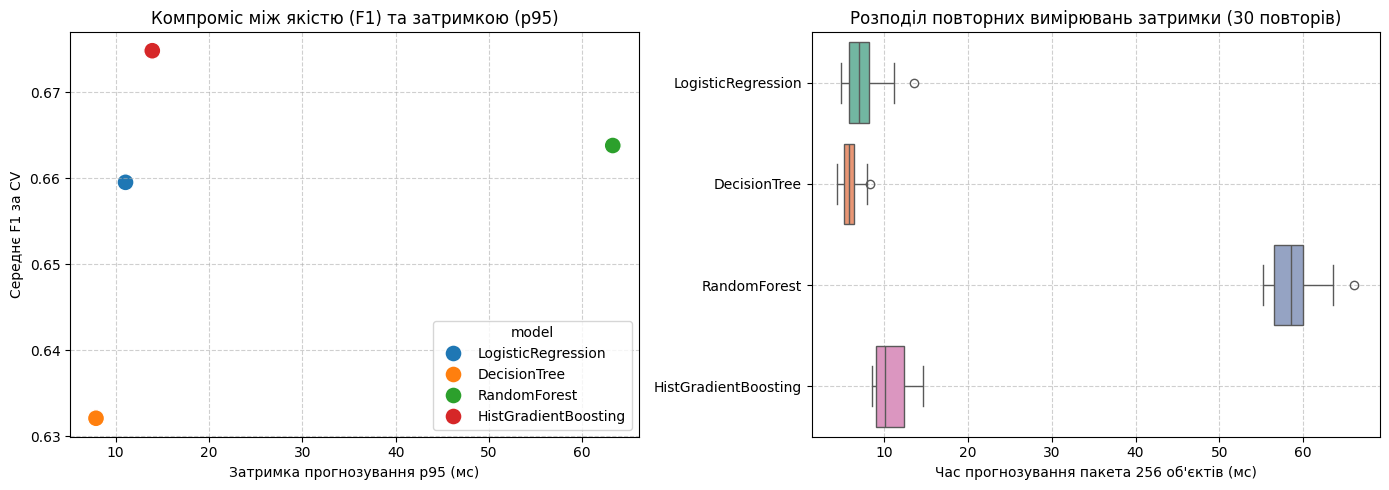

Файл configs/realtime_service.json успішно згенеровано.


In [2]:
import time
import joblib
import os
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Створення необхідних папок
os.makedirs("artifacts", exist_ok=True)
os.makedirs("configs", exist_ok=True)
os.makedirs("results", exist_ok=True)

# --- 4. Реалізація профілювання ---
def profile_prediction(model, batch, warmups=5, repeats=30):
    # Прогрів
    for _ in range(warmups):
        model.predict(batch)
        
    samples = []
    for _ in range(repeats):
        start = time.perf_counter_ns()
        model.predict(batch)
        elapsed_ms = (time.perf_counter_ns() - start) / 1_000_000
        samples.append(elapsed_ms)
        
    samples = np.array(samples)
    p50 = np.percentile(samples, 50)
    p95 = np.percentile(samples, 95)
    
    # Пропускна здатність (об'єктів за секунду)
    throughput = (len(batch) / (p50 / 1000)) if p50 > 0 else 0
    
    return p50, p95, throughput, samples

batch_data = X_test.iloc[:256]
profiling_results = []
latency_samples_dict = {}

print("=== Початок профілювання кандидатів ===")
for name, pipeline in candidates.items():
    # Вимірювання часу навчання
    start_train = time.perf_counter()
    pipeline.fit(X_train, y_train)
    fit_time = time.perf_counter() - start_train
    
    # Серіалізація та розмір
    model_path = f"artifacts/{name}.joblib"
    joblib.dump(pipeline, model_path)
    model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
    
    # Вимірювання затримки
    p50, p95, throughput, lat_samples = profile_prediction(pipeline, batch_data)
    latency_samples_dict[name] = lat_samples
    
    profiling_results.append({
        "Model": name,
        "fit_time_s": fit_time,
        "latency_p50_ms": p50,
        "latency_p95_ms": p95,
        "throughput_samples_s": throughput,
        "model_size_mb": model_size_mb
    })

df_profiling = pd.DataFrame(profiling_results)

# --- 5. Формування матриці результатів ---
df_benchmark = pd.merge(df_cv_summary, df_profiling, on="Model")
df_benchmark.columns = ['model', 'cv_f1_mean', 'cv_f1_std', 'cv_recall_mean', 
                        'cv_roc_auc_mean', 'cv_bal_acc_mean', 'fit_time_s', 
                        'latency_p50_ms', 'latency_p95_ms', 'throughput_samples_s', 'model_size_mb']

df_benchmark.to_csv("results/benchmark_results.csv", index=False)
print("Файл results/benchmark_results.csv успішно збережено.")
display(df_benchmark.round(4))

# Графіки
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Якість проти Затримки
sns.scatterplot(data=df_benchmark, x="latency_p95_ms", y="cv_f1_mean", hue="model", s=150, ax=axes[0])
axes[0].set_title("Компроміс між якістю (F1) та затримкою (p95)")
axes[0].set_xlabel("Затримка прогнозування р95 (мс)")
axes[0].set_ylabel("Середнє F1 за CV")
axes[0].grid(True, linestyle='--', alpha=0.6)

# Графік 2: Розподіл вимірювань затримки
df_latency = pd.DataFrame(latency_samples_dict)
sns.boxplot(data=df_latency, orient="h", ax=axes[1], palette="Set2")
axes[1].set_title("Розподіл повторних вимірювань затримки (30 повторів)")
axes[1].set_xlabel("Час прогнозування пакета 256 об'єктів (мс)")
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# --- 6. Створення конфігурації сценарію ---
scenario_config = {
    "scenario_name": "realtime_edge_service",
    "description": "Синхронний сервіс на периферійному обладнанні",
    "constraints": {
        "cv_recall_mean": {"min": 0.40},
        "latency_p95_ms": {"max": 10.0},
        "model_size_mb": {"max": 5.0}
    },
    "criteria": {
        "cv_f1_mean": {
            "direction": "maximize",
            "weight": 0.50,
            "worst": 0.60,
            "best": 0.70
        },
        "latency_p95_ms": {
            "direction": "minimize",
            "weight": 0.30,
            "worst": 10.0,
            "best": 1.0
        },
        "cv_roc_auc_mean": {
            "direction": "maximize",
            "weight": 0.20,
            "worst": 0.80,
            "best": 0.90
        }
    }
}

with open("configs/realtime_service.json", "w", encoding="utf-8") as f:
    json.dump(scenario_config, f, indent=4, ensure_ascii=False)
print("Файл configs/realtime_service.json успішно згенеровано.")

In [3]:
# --- 7. Реалізація перевірки обмежень ---
def check_constraints(row, constraints):
    violations = []
    for metric, limits in constraints.items():
        if metric not in row or pd.isna(row[metric]):
            violations.append(f"{metric}: missing value")
            continue
            
        value = float(row[metric])
        if "min" in limits and value < float(limits["min"]):
            violations.append(f"{metric}: below minimum (got {value:.4f}, need >= {limits['min']})")
        if "max" in limits and value > float(limits["max"]):
            violations.append(f"{metric}: above maximum (got {value:.4f}, need <= {limits['max']})")
            
    return len(violations) == 0, violations

# --- 8. Реалізація нормалізації ---
def normalize_value(value, specification):
    direction = specification["direction"]
    worst = float(specification["worst"])
    best = float(specification["best"])
    val = float(value)
    
    if direction == "maximize":
        normalized = (val - worst) / (best - worst)
    elif direction == "minimize":
        normalized = (worst - val) / (worst - best)
    else:
        raise ValueError(f"Unknown direction: {direction}")
        
    return float(np.clip(normalized, 0.0, 1.0))

# --- 9. Реалізація рейтингу ---
def rank_models(results_df, config):
    constraints = config.get("constraints", {})
    criteria = config.get("criteria", {})
    
    eligible_records = []
    rejected_records = []
    
    for _, row in results_df.iterrows():
        model_name = row['model']
        is_eligible, violations = check_constraints(row, constraints)
        
        if not is_eligible:
            rejected_records.append({
                "model": model_name,
                "violations": " | ".join(violations)
            })
            continue
            
        # Розрахунок зваженого бала для допустимих моделей
        total_score = 0.0
        norm_details = {"model": model_name}
        
        for metric, spec in criteria.items():
            if metric in row:
                norm_val = normalize_value(row[metric], spec)
                weight = float(spec["weight"])
                total_score += norm_val * weight
                norm_details[f"norm_{metric}"] = norm_val
            
        norm_details["final_score"] = total_score
        eligible_records.append(norm_details)
        
    df_eligible = pd.DataFrame(eligible_records)
    df_rejected = pd.DataFrame(rejected_records)
    
    if not df_eligible.empty:
        # Сортування за балом (спадання), а при нічиїй - за назвою (зростання)
        df_eligible = df_eligible.sort_values(by=["final_score", "model"], ascending=[False, True]).reset_index(drop=True)
        df_eligible.insert(0, "rank", range(1, len(df_eligible) + 1))
        
    return df_eligible, df_rejected

# Завантажуємо наші збережені результати та конфігурацію Edge-сервісу
df_benchmark = pd.read_csv("results/benchmark_results.csv")
with open("configs/realtime_service.json", "r", encoding="utf-8") as f:
    config_realtime = json.load(f)

# Виконуємо ранжування
df_eligible, df_rejected = rank_models(df_benchmark, config_realtime)

print("=== Допустимі моделі (Рейтинг) ===")
display(df_eligible.round(4) if not df_eligible.empty else "Немає допустимих моделей!")

print("\n=== Відхилені моделі ===")
display(df_rejected)

=== Допустимі моделі (Рейтинг) ===


,rank,model,norm_cv_f1_mean,norm_latency_p95_ms,norm_cv_roc_auc_mean,final_score
0,1,DecisionTree,0.3208,0.2341,0.2805,0.2868



=== Відхилені моделі ===


,model,violations
0,LogisticRegression,"latency_p95_ms: above maximum (got 11.0560, ne..."
1,RandomForest,"latency_p95_ms: above maximum (got 63.2681, ne..."
2,HistGradientBoosting,"latency_p95_ms: above maximum (got 13.9252, ne..."


=== Артефакти для Real-time сценарію збережено. ===

=== Допустимі моделі (Сценарій: Пакетне опрацювання) ===


,rank,model,norm_cv_f1_mean,norm_cv_roc_auc_mean,norm_latency_p95_ms,final_score
0,1,HistGradientBoosting,0.7484,0.5522,0.8694,0.7016
1,2,LogisticRegression,0.5953,0.5565,0.8984,0.6139
2,3,RandomForest,0.6381,0.6073,0.3710,0.6021
3,4,DecisionTree,0.3208,0.2805,0.9304,0.3697


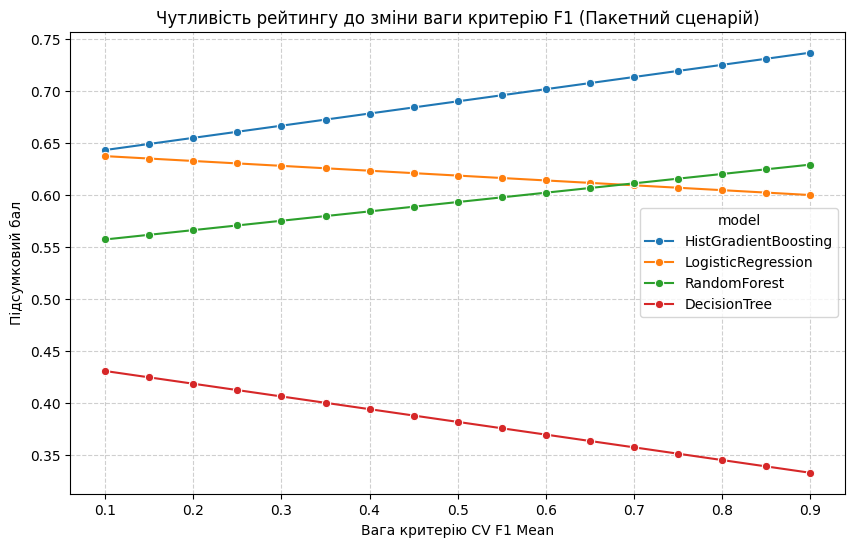

In [6]:
import shutil

# --- 10. Збереження результату ---
def save_results(scenario_name, df_eligible, df_rejected, config):
    # CSV
    df_eligible.to_csv(f"results/ranking_{scenario_name}.csv", index=False)
    df_rejected.to_csv(f"results/rejected_{scenario_name}.csv", index=False)
    
    primary_model = df_eligible.iloc[0]['model'] if not df_eligible.empty else None
    reserve_model = df_eligible.iloc[1]['model'] if len(df_eligible) > 1 else None
    
    # JSON підсумок
    summary = {
        "scenario": scenario_name,
        "config_version": "1.0",
        "primary_model": primary_model,
        "reserve_model": reserve_model,
        "eligible_count": len(df_eligible),
        "rejected_count": len(df_rejected)
    }
    with open(f"results/selection_{scenario_name}.json", "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=4)
        
    # Markdown звіт
    with open(f"results/MODEL_SELECTION_{scenario_name}.md", "w", encoding="utf-8") as f:
        f.write(f"# Звіт про вибір моделі: {scenario_name}\n\n")
        f.write(f"**Основна модель:** {primary_model}\n")
        f.write(f"**Резервна модель:** {reserve_model}\n\n")
        f.write("## Рейтинг\n")
        f.write(df_eligible.to_markdown(index=False) if not df_eligible.empty else "Немає допустимих моделей.")
        f.write("\n\n## Відхилені моделі\n")
        f.write(df_rejected.to_markdown(index=False))
        
    # Копіювання артефактів
    if primary_model:
        shutil.copy(f"artifacts/{primary_model}.joblib", f"artifacts/selected_primary_{scenario_name}.joblib")
    if reserve_model:
        shutil.copy(f"artifacts/{reserve_model}.joblib", f"artifacts/selected_reserve_{scenario_name}.joblib")

save_results("realtime_edge", df_eligible, df_rejected, config_realtime)
print("=== Артефакти для Real-time сценарію збережено. ===")

# --- 11. Другий інженерний сценарій (Пакетне опрацювання) ---
config_batch = {
    "scenario_name": "batch_processing",
    "description": "Нічне пакетне опрацювання на сервері",
    "constraints": {
        "cv_recall_mean": {"min": 0.40},
        "latency_p95_ms": {"max": 100.0},
        "model_size_mb": {"max": 10.0}
    },
    "criteria": {
        "cv_f1_mean": {"direction": "maximize", "weight": 0.60, "worst": 0.60, "best": 0.70},
        "cv_roc_auc_mean": {"direction": "maximize", "weight": 0.30, "worst": 0.80, "best": 0.90},
        "latency_p95_ms": {"direction": "minimize", "weight": 0.10, "worst": 100.0, "best": 1.0}
    }
}

with open("configs/batch_service.json", "w", encoding="utf-8") as f:
    json.dump(config_batch, f, indent=4)

df_eligible_batch, df_rejected_batch = rank_models(df_benchmark, config_batch)
save_results("batch_processing", df_eligible_batch, df_rejected_batch, config_batch)

print("\n=== Допустимі моделі (Сценарій: Пакетне опрацювання) ===")
display(df_eligible_batch.round(4))

# --- 12. Аналіз чутливості ---
def sensitivity_analysis(results_df, base_config, target_metric="cv_f1_mean", weight_range=np.arange(0.1, 0.95, 0.05)):
    sensitivity_records = []
    
    # Визначаємо інші метрики для пропорційного перерахунку
    other_metrics = [m for m in base_config["criteria"].keys() if m != target_metric]
    base_other_weights_sum = sum(base_config["criteria"][m]["weight"] for m in other_metrics)
    
    for w_target in weight_range:
        temp_config = eval(repr(base_config)) # Глибока копія
        temp_config["criteria"][target_metric]["weight"] = w_target
        
        # Перераховуємо інші ваги пропорційно
        remaining_weight = 1.0 - w_target
        for m in other_metrics:
            original_w = temp_config["criteria"][m]["weight"]
            temp_config["criteria"][m]["weight"] = (original_w / base_other_weights_sum) * remaining_weight if base_other_weights_sum > 0 else 0
            
        df_el, _ = rank_models(results_df, temp_config)
        if not df_el.empty:
            for _, row in df_el.iterrows():
                sensitivity_records.append({
                    "target_weight": w_target,
                    "model": row["model"],
                    "final_score": row["final_score"]
                })
                
    return pd.DataFrame(sensitivity_records)

df_sens = sensitivity_analysis(df_benchmark, config_batch, target_metric="cv_f1_mean")

plt.figure(figsize=(10, 6))
sns.lineplot(data=df_sens, x="target_weight", y="final_score", hue="model", marker="o")
plt.title("Чутливість рейтингу до зміни ваги критерію F1 (Пакетний сценарій)")
plt.xlabel("Вага критерію CV F1 Mean")
plt.ylabel("Підсумковий бал")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()